# FINAL PROJECT - GROUP 15 - QUESTION FOMULATION

## 1.1 Khai báo thư viện và đọc dữ liệu đã xử lý

Khai báo thư viện cần thiết

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
sys.path.append("..")

from src import config
from src.preprocess import DataProcessor
from src.eda import GroupedAnalyzer
from src.visualize import SHAPPlotter, Plotter
from src.model import Clusterer, RandomForestPredictor, LinearRegressionPredictor

Đọc dữ liệu đã xử lý

In [2]:
df = DataProcessor.load_data(config.PROCESSED_DATA_DIR)

Kích thước: 989 dòng, 19 cột


## 2 Các câu hỏi phân tích dữ liệu

### 2.1 Việc phụ thuộc nhiều vào AI ảnh hưởng tốt hay xấu năng suất?

Tức là kiểm tra xem `AI_Intensity` ảnh hưởng như thế nào đến `Lines_of_code, Bug_Rate`

In [3]:
metrics = [config.FEATURE_EFFICIENCY_LOC, config.FEATURE_BUG_RATE, 'Task_Success_Rate']
ai_summary = GroupedAnalyzer.analyze_by_group(df, config.FEATURE_AI_USER_TYPE, metrics, observed=False)
ai_summary

,Efficiency_LOC_per_Hour,Bug_Rate_per_1k_LOC,Task_Success_Rate
AI_User_Type,,,
Extreme AI,33.40,52.63,60.76
High AI,38.02,35.01,59.76
Low AI,46.08,49.83,51.15
Moderate AI,41.60,29.20,55.56


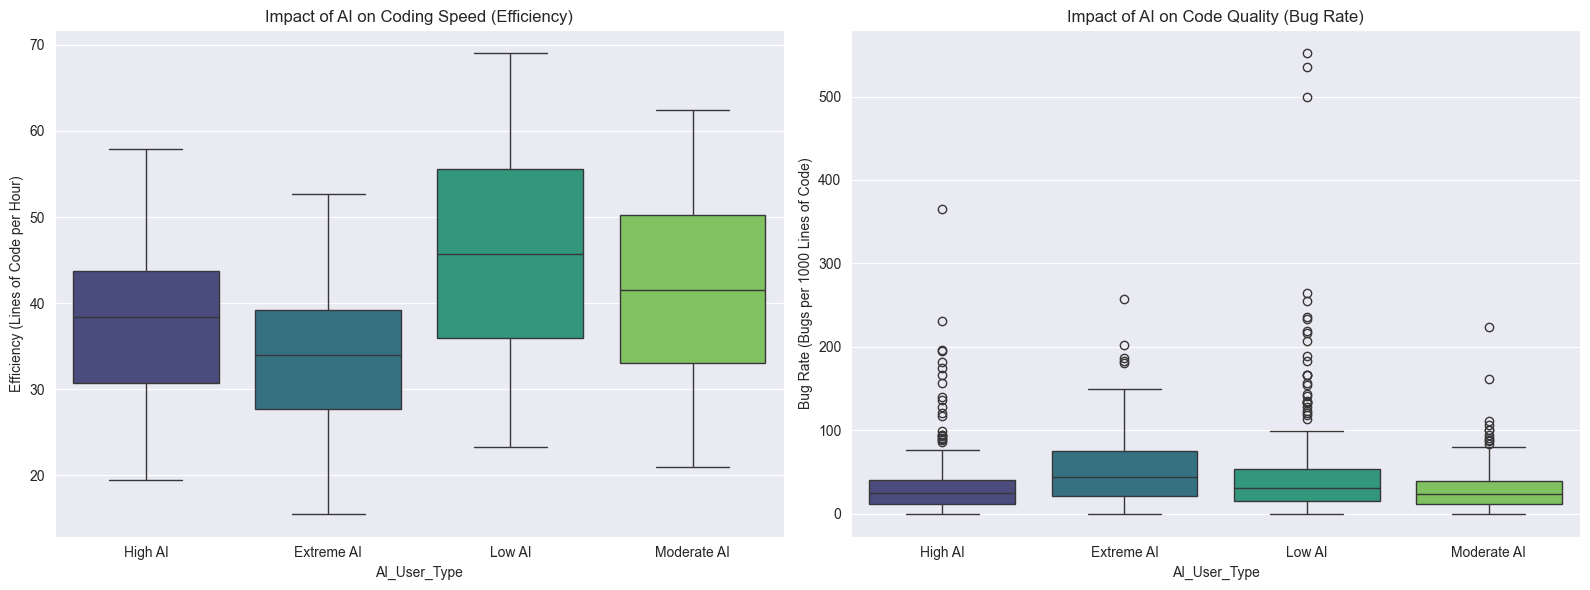

In [4]:
Plotter.multi_boxplots(df,
                       x=config.FEATURE_AI_USER_TYPE,
                       y_cols=[config.FEATURE_EFFICIENCY_LOC, config.FEATURE_BUG_RATE],
                       titles=['Impact of AI on Coding Speed (Efficiency)', 'Impact of AI on Code Quality (Bug Rate)'],
                       ylabels=['Efficiency (Lines of Code per Hour)', 'Bug Rate (Bugs per 1000 Lines of Code)'])

**Quan sát:**
- `AI_Intensity` càng cao, `Efficiency` (số dòng code/giờ) càng giảm (từ 46 xuống 33). Điều này có khả năng cao là do những người dùng "Extreme AI" đang dành quá nhiều thời gian để viết prompt, hoặc sửa bug do AI tạo ra (Do quá phụ thuộc vào AI nên không review hoặc prompt kĩ, dẫn tới kết quả tạo ra của AI sai).
- `Bug_Rate` cao (49.8) ở người dùng "Low AI", trong khi thấp nhất (29.2 - 35.0) ở "Moderate/High AI", giá trị này lại tăng (52.6) ở "Extreme AI". Điều này có nghĩa là nếu ít sử dụng AI thì bug do con người sinh ra sẽ nhiều, nhưng nếu lạm dụng thì bug do AI lại nhiều. Do đó, biết cân bằng là tốt nhất.
- Mặc dù vậy, sử dụng AI càng nhiều thì tỉ lệ hoàn thành task lại càng cao. Đặc biệt, nhóm "Extreme AI" lại có `Task_Success_Rate` cao nhất (60.7). Những người dùng AI nhiều có thể giải quyết vấn đề khó tốt hơn, hoặc xử lí được nhiều vấn đề hơn, dù code của họ hơi tệ và phải sửa nhiều bug.

=> **Kết luận:** Việc phụ thuộc quá ít vào AI thì không tốt. Việc phụ thuộc quá nhiều, mặc dù có thể giúp tăng tỉ lệ hoàn thành task, nhưng tỉ lệ fix bug và effiency lại giảm tương ứng. Do đó, chúng ta nên kết hợp việc sử dụng AI với năng lực của chính bản thân, review code kĩ, không phụ thuộc hoàn toàn vào AI.

### 2.2 Mức độ stress ảnh hưởng như nào thế nào đến hiệu suất công việc?

Sử dụng `Task_Success_Rate` làm hiệu suất công việc

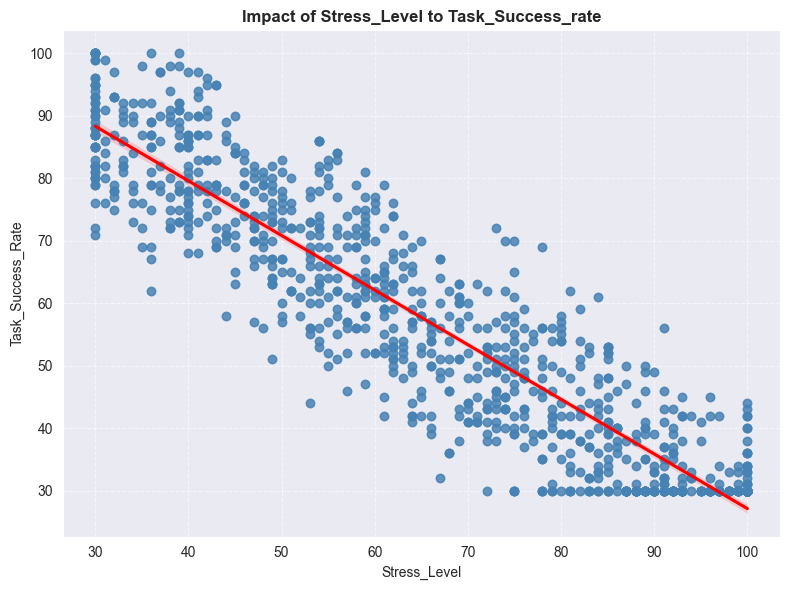

In [5]:
Plotter.scatter(df, x='Stress_Level', y='Task_Success_Rate',
                 title='Impact of Stress_Level to Task_Success_rate',
                 xlabel='Stress_Level', ylabel='Task_Success_Rate', line_color='red')

**Quan sát:** Khi mức độ Stress tăng, hiệu suất công việc có xu hướng giảm. Tuy nhiên, sự phân tán dữ liệu rộng cho thấy ở một số mức stress trung bình, vẫn có những cá nhân duy trì hiệu suất task cao, chỉ ra sự phức tạp và ảnh hưởng của các yếu tố khác.

### 2.3 Những kiểu lập trình viên nào sẽ có hiệu suất cao nhất? 

- Chỉ xét dựa trên các features `Hours_Coding`, `AI_Usage_Hours`, `Sleep_Hours`, `Efficiency_LOC_per_Hour`, `Stress_Level`.
- Nhóm em sẽ sử dụng K-means Clustering với k = 3 để tìm ra các nhóm lập trình viên có hiệu suất cao nhất dựa trên những đặc trưng đã nêu. Mục đích của việc sử dụng K-means là để giúp cho việc tìm hiểu xem những nhóm lập trình viên nào thường có hiệu suất cao nhất cũng như những đặc trưng riêng của từng nhóm thể hiện qua các features, qua đó hiểu được mối quan hệ giữa các features này với nhau để tạo ra hiệu suất cao.

In [6]:
cluster_features = ['Hours_Coding', 'AI_Usage_Hours', 'Sleep_Hours',
                    config.FEATURE_EFFICIENCY_LOC, 'Stress_Level']

clusterer = Clusterer(n_clusters=3, label_col='Developer_Type')
df, cluster_summary = clusterer.fit_predict(df, cluster_features)

cluster_summary

,Hours_Coding,AI_Usage_Hours,Sleep_Hours,Efficiency_LOC_per_Hour,Stress_Level,Task_Success_Rate
Developer_Type,,,,,,
0,4.77,3.82,6.58,35.36,45.74,77.02
1,5.13,3.37,6.36,34.84,85.91,40.19
2,7.64,1.46,6.41,51.88,63.96,55.16


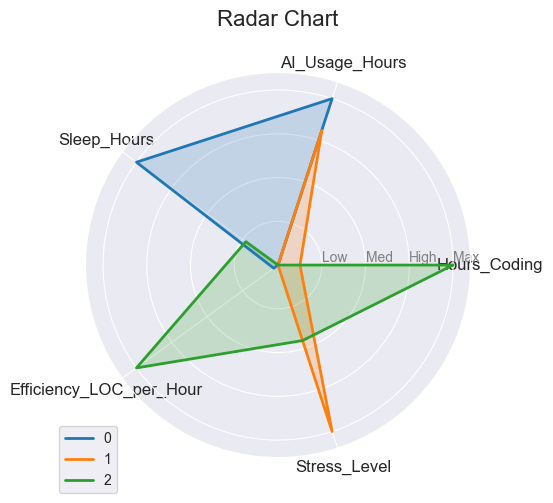

In [7]:
Plotter.radar(cluster_summary, cluster_features, figsize=(5, 5), colors=['#1f77b4', '#ff7f0e', '#2ca02c'])

In [8]:
print(df.groupby('Developer_Type')['Task_Success_Rate'].mean().sort_values(ascending=False))

Developer_Type
0    77.015873
2    55.158416
1    40.188679
Name: Task_Success_Rate, dtype: float64


**Quan sát:**
- Cluster 2 (Xanh lá):
    *   Đặc điểm: Ngủ nhiều nhất (6.6h), Dùng AI nhiều nhất (3.8h), Stress thấp nhất (45), Code tay ít nhất (4.7h).
    *   Kết quả: `Task_Success_Rate` cao nhất (77%).
    *   Insight: Những người này làm việc thông minh, tận dụng AI để giảm tải công việc thủ công, ngủ đủ giấc. Kết quả là họ thành công nhất.

- Cluster 0 (Xanh dương):
    *   Đặc điểm: Trâu nhất. Code tay tận 7.6h/ngày, tốc độ gõ code nhanh khủng khiếp (Efficiency 51.8), ít dùng AI.
    *   Kết quả: `Task_Success_Rate` trung bình (54%).
    *   Insight: Đây là kiểu lập trình viên truyền thống. Làm việc chăm chỉ, nhưng hiệu quả không tối ưu bằng nhóm biết dùng công nghệ. Họ đang đánh đổi thời gian lấy kết quả ở mức trung bình.

- Cluster 1 (Cam):
    *   Đặc điểm: Stress lớn nhất (85.8), dù thời gian code và sử dụng AI không cao, chỉ ở mức trung bình so với các nhóm khác (5.2h).
    *   Kết quả: Thất bại nhất (40.4%).
    *   Insight: Nhóm này đang gặp vấn đề nghiêm trọng nào đó, nhưng chưa biết rõ lí do.

### 2.4 Với từng cá nhân cụ thể, yếu tố nào đang kéo tụt hiệu suất của họ và yếu tố nào đang nâng họ lên?

- Mục tiêu: Dự đoán chính xác Task_Success_Rate (0-100)
- Loại bỏ các cột kết quả (Success, Stress) ra khỏi các đặc trung đầu vào, chỉ giữ lại các đặc trưng về hành vi

Đầu tiên, nhóm sẽ sử dụng một mô hình machine learning ngẫu nhiên (Như Random Forest) để đưa ra dự đoán. Sau đó sử dụng SHAP value để tìm hiểu sự đóng góp của từng features, qua đó trả lời được cho câu hỏi trên.

In [9]:
shap_features = ['Hours_Coding', 'AI_Usage_Hours', 'Sleep_Hours',
                 'Commits', 'Lines_of_Code', 'Coffee_Intake', 'Cognitive_Load']
X = df[shap_features]
y = df['Task_Success_Rate']

X_train, X_test, y_train, y_test = DataProcessor.split_data(X, y)

Kích thước tập huấn luyện: (791, 7)
Kích thước tập kiểm tra: (198, 7)


Huấn luyện mô hình random forest

In [10]:
predictor = RandomForestPredictor()
predictor.train(X_train, y_train)
predictor.evaluate(X_test, y_test)

Model Evaluation:
  R-squared: 0.9569
  RMSE: 4.3282
  MAE: 3.4720


{'r2_score': 0.9569275526787642,
 'rmse': np.float64(4.328214342421063),
 'mae': 3.472020202020202}

Mô hình có R-squared rất cao, vì vậy ta có thể tin tưởng được

Tiếp theo, chúng em sử dụng SHAP values để giải thích các kết quả của mô hình

In [11]:
# Tính SHAP Values
shap_analyzer = SHAPPlotter(predictor.model)
shap_values = shap_analyzer.compute_shap_values(X_test)

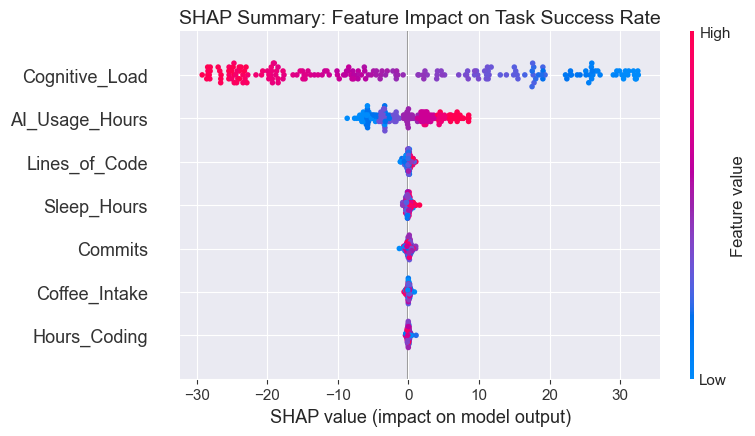

In [12]:
# Visualization 1: SHAP
shap_analyzer.plot_summary(X_test, "SHAP Summary: Feature Impact on Task Success Rate")

**Quan sát biểu đồ :**
- Dải màu biến thiên của `Cognitive_Load` rất rộng (từ -30 đến +35 SHAP value). Các điểm đỏ (High Cognitive Load) nằm hoàn toàn bên trái (Negative Impact). Các điểm xanh (Low Cognitive Load) nằm hoàn toàn bên phải (Positive Impact). Nói cách khác, `Cognitive_Load` cao sẽ khiến cho `Task_Success_Rate` giảm mạnh.
- Dải màu biến thiên của `AI_Usage_Hours` thì nhỏ hơn (Từ -8 đến 8). Các điểm đỏ (Dùng AI nhiều) có xu hướng nằm bên phải (Positive Impact), trong khi điểm xanh (Dùng AI ít) có hướng nằm bên tái (Negative Impact). Nói cách khác, dùng AI nhiều sẽ giúp tăng `Task_Success_Rate`.
- Những features khác `Hours_Coding` & `Coffee_Intake` thì có ảnh hưởng không quá mạnh với `Task_Success_Rate`, bằng chứng là SHAP value của chúng đều rất thấp. Nói cách khác, làm việc nhiều hay uống nhiều cà phê hầu như không tác động đáng kể đến sự thành công của dự án trong mô hình này.

=> **Kết luận:** Để tăng hiệu suất, ưu tiên hàng đầu là giảm `Cognitive_Load` và sử dụng AI nhiều hơn, với mức độ phù hợp.

<Figure size 800x600 with 0 Axes>

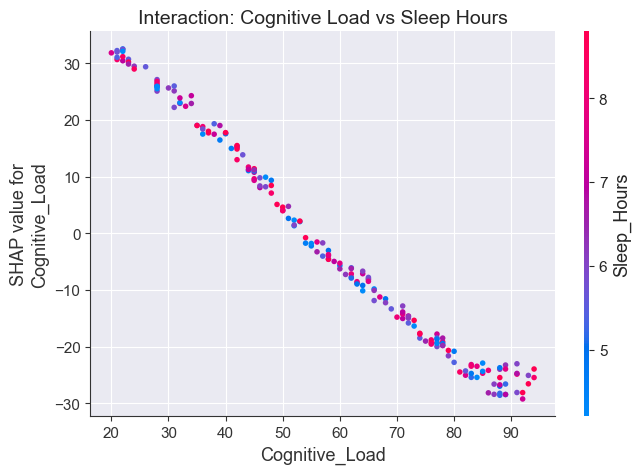

In [13]:
# Visualization 2: SHAP Dependence Plot
# Xem tác động của Cognitive Load thay đổi thế nào khi kết hợp với Sleep Hours
shap_analyzer.plot_dependence(X_test, "Cognitive_Load", "Sleep_Hours", "Interaction: Cognitive Load vs Sleep Hours")

**Quan sát biểu đồ:** 
- Ban đầu, chúng em đặt ra câu hỏi là tại sao `Sleep_Hours` lại ít liên quan đến hiệu suất đến vậy. Do đó, chúng em vẽ thêm 1 plot để check xem `Sleep_Hours` có ảnh hưởng đến áp lực `Cognitive_load` hay không.
- Kết quả cho thấy màu của `Sleep_Hours` phân bố khá đều từ thấp đến cao trên toàn bộ miền giá trị của `Cognitive_Load`.

=> **Kết luận:** Trên thực tế, áp lực không đến từ việc ngủ ít hay nhiều, mà có thể xuất phát từ các yếu tố khác.

### 2.5 Liệu việc gia tăng tiêu thụ cà phê có thực sự thúc đẩy năng suất làm việc hay sẽ tạo ra nhiều ảnh hưởng tiêu cực hơn?

Trước tiên, chúng ta sẽ chia các lập trình viên ra làm 3 nhóm tiêu thụ cà phê

In [14]:
metrics = [config.FEATURE_EFFICIENCY_LOC, 'Bugs_Found', 'Stress_Level', 'Task_Success_Rate']
coffee_summary = GroupedAnalyzer.analyze_by_group(df, config.FEATURE_COFFEE_GROUP, metrics, observed=True)
coffee_summary

,Efficiency_LOC_per_Hour,Bugs_Found,Stress_Level,Task_Success_Rate
Coffee_Group,,,,
High (>4 cups),40.57,9.87,67.84,55.15
Low (0-2 cups),39.85,9.72,65.97,57.06
Medium (3-4 cups),40.33,10.02,64.97,57.57


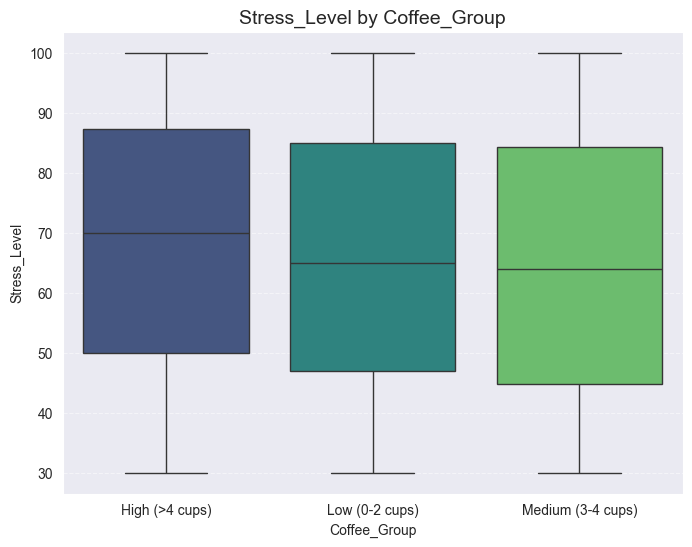

In [15]:
# Visualize 1: Impact of Coffee on Stress Levels
Plotter.boxplot(df, x=config.FEATURE_COFFEE_GROUP, y='Stress_Level')

**Quan sát:**
-   Cả ba nhóm tiêu thụ cà phê đều có mức trung vị xấp xỉ nhau giao động từ mức 65 - 70.
-   Nhóm tiêu thụ cà phê cao có vẻ dịch chuyển lên một chút so với hai nhóm thấp và trung bình.

=> Sự khác biệt có vẻ không quá rõ ràng giữa tiêu thụ và phê thấp và tiêu thụ cà phê cao. cần sử dụng thêm kiểm định `ANOVA` để có thể khẳng định sự khác biệt.

In [16]:
f_stat, p_value = GroupedAnalyzer.perform_one_way_anova(df, config.FEATURE_COFFEE_GROUP, 'Stress_Level')
print("Kiểm định ANOVA một yếu tố cho mức độ stress theo nhóm tiêu thụ cà phê:")
print(f"  - F-statistic: {f_stat:.4f}")
print(f"  - P-value: {p_value:.4f}")

Kiểm định ANOVA một yếu tố cho mức độ stress theo nhóm tiêu thụ cà phê:
  - F-statistic: 1.3414
  - P-value: 0.2620


=> Không có sự khác biệt có ý nghĩa thống kê giữa các nhóm (p_value > 0.05). Vì vậy, có vẻ số lượng cà phê tiêu thụ không ảnh hưởng đến mức độ stress.

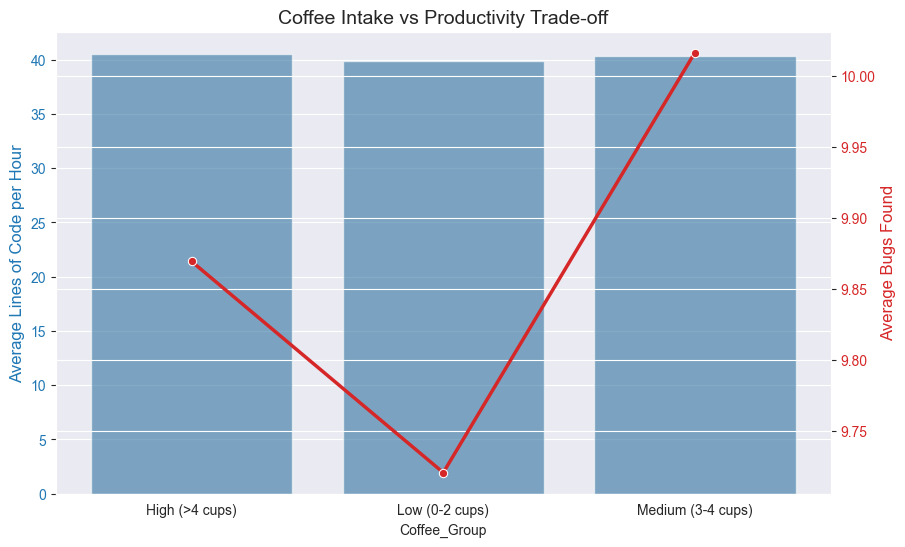

In [17]:
# Visualize 2: Plot of Coffee and Productivity Trade-off
Plotter.dual_axis(df, x=config.FEATURE_COFFEE_GROUP,
                  y1=config.FEATURE_EFFICIENCY_LOC, y2 ='Bugs_Found',
                  figsize=(10, 6), title='Coffee Intake vs Productivity Trade-off',
                  y1_label='Average Lines of Code per Hour', y2_label='Average Bugs Found')

**Quan sát:**
-   Số lượng dòng code được tạo ra có vẻ tăng lên một chút khi lập trình viên uống nhiều cà phê. Điều này chỉ ra rằng người uống nhiều cà phê sẽ làm việc nhiều hơn một chút.
-   Số lượng lỗi (bugs) có sự biến động nhưng không theo xu hướng rõ ràng. Tuy nhiên, số lượng bug của nhóm uống ít cà phê có vẻ ít hơn nhiều so với nhóm trung bình và cao ủng hộ giả thuyết rằng những người uống ít cà phê thường là những người đủ tỉnh táo và tạo ra ít lỗi hơn.

**Kết luận cho câu hỏi:** Việc gia tăng tiêu thụ cà phê có thúc đẩy nhẹ năng suất làm việc nhưng mang lại hiệu quả tiêu cực nhiều hơn tích cực:
- Lập trình viên không viết được nhiều code hơn đáng kể.
- Lập trình viên tạo ra nhiều lỗi hơn, đặc biệt ở mức tiêu thụ trung bình.

### 2.6 Hiệu quả của việc sử dụng công cụ AI đối với tỷ lệ thành công của nhiệm vụ thay đổi như thế nào giữa nhóm lập trình viên có trạng thái tinh thần ổn định so với nhóm đang bị quá tải ?

Ở đây, để phân ra hai nhóm lập trình viên có tinh thần ổn định và quá tải chúng em  sử dụng `K-mean clustering` với số `cluster = 2` và các đặc trưng được sử dụng là `Stress_level` và `Cognitive_Load`.

In [18]:
cluster_features = ['Stress_Level', 'Cognitive_Load']
clusterer = Clusterer(n_clusters=2, label_col='Mental_State', labels=['Stable', 'Overloaded'])
df, cluster_summary = clusterer.fit_predict(df, cluster_features)

cluster_summary

,Stress_Level,Cognitive_Load,Task_Success_Rate
Mental_State,,,
Overloaded,47.51,38.17,73.68
Stable,85.47,75.87,39.15


Để biết hiệu quả thực tế của việc sử dụng công cụ AI với tỷ lệ thành công của nhiệm vụ, ta sử dụng mô hình linear regression với các đặc trưng có liên quan.
- Các đặc trưng được sử dụng: `AI_Usage_Hours`, `Sleep_Hours`, `Coffee_Intake`, `Stress_Level`, `Cognitive_Load`, `Hours_Coding`,
- Target của mô hình: `Task_Success_Rate`

In [19]:
groups = df['Mental_State'].unique()
results = {}

features = ['AI_Usage_Hours', 'Sleep_Hours', 'Coffee_Intake',
            'Stress_Level', 'Cognitive_Load', 'Hours_Coding']
target = 'Task_Success_Rate'

for group in groups:
    print(f"Group: {group}")
    group_df = df[df['Mental_State'] == group]

    X = group_df[features]
    y = group_df[target]
    X_train, X_test, y_train, y_test = DataProcessor.split_data(X, y)

    # Train Model (Linear Regression)
    predictor = LinearRegressionPredictor()
    predictor.train(X_train, y_train)
    metrics = predictor.evaluate(X_test, y_test)

    y_pred = predictor.predict(X_test)
    results[group] = {
        'coefficients': predictor.get_coefficients(),
        'metrics': metrics,
        'y_test': y_test,
        'y_pred': y_pred,
        'model': predictor
    }
    print("-" * 30)

Group: Stable
Kích thước tập huấn luyện: (393, 6)
Kích thước tập kiểm tra: (99, 6)
Model Evaluation:
  R-squared: 0.7567
  RMSE: 4.6068
  MAE: 3.8775
------------------------------
Group: Overloaded
Kích thước tập huấn luyện: (397, 6)
Kích thước tập kiểm tra: (100, 6)
Model Evaluation:
  R-squared: 0.8127
  RMSE: 5.5493
  MAE: 4.8801
------------------------------


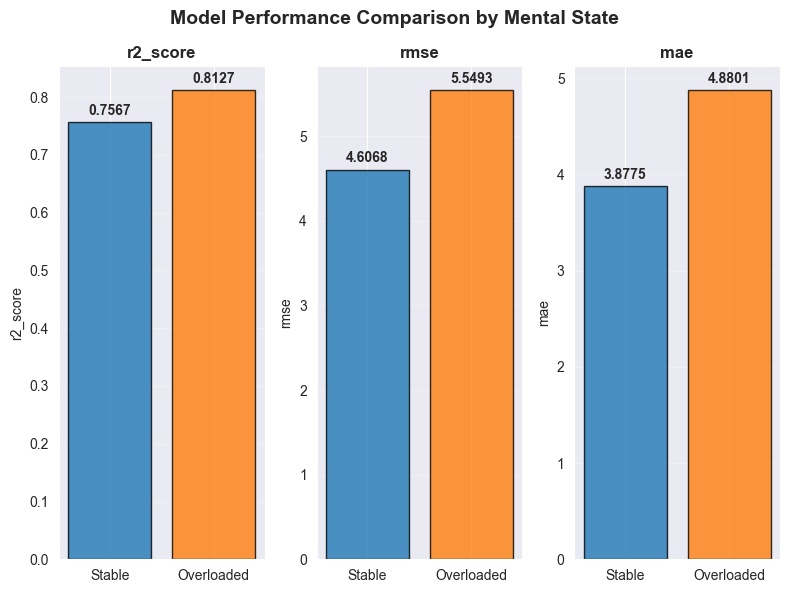

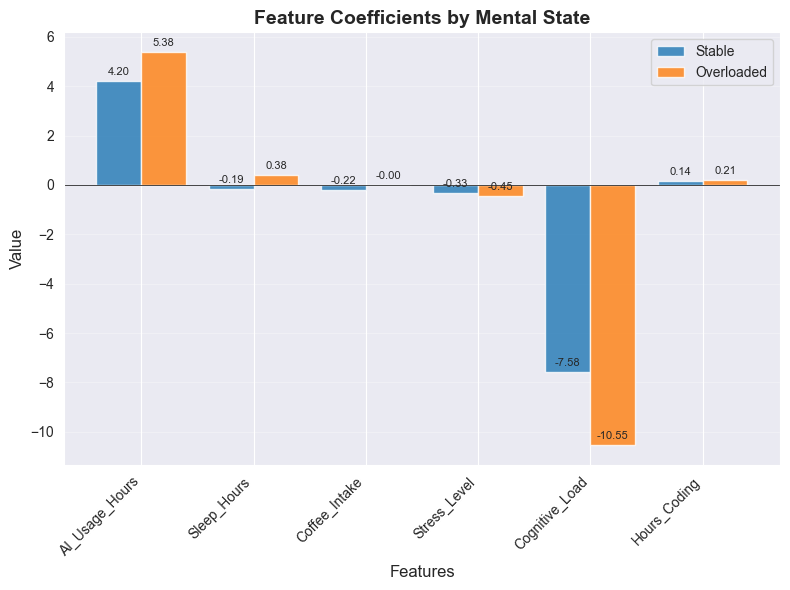

In [20]:
# Visualize coefficients & metrics
Plotter.metrics_bars(results, figsize=(8, 6),
                     title='Model Performance Comparison by Mental State')

Plotter.grouped_bars(results, value_key='coefficients', figsize=(8, 6),
                     title='Feature Coefficients by Mental State')

**Quan sát:**
- Mô hình có R-squared khá cao (0.7567 và 0.8127), vì vậy ta có thể tin tưởng được.
- Nhóm lập trình viên có trạng thái tinh thần ổn định tận dụng công cụ AI hiệu quả hơn hẳn. Hệ số hồi quy của nhóm này là 5.38, cao hơn so với nhóm quá tải là 4.27.
- Tỷ lệ chênh lệch: $\frac{\text{Hệ số stable} - \text{hệ số overload}}{\text{hệ số overload}} * 100\%$ = $\frac{5.38 - 4.27}{4.27} * 100\% \approx 26\%$

=> Với cùng một lượng thời gian sử dụng AI, nhóm có tinh thần ổn định chuyển hóa công cụ thành tỷ lệ thành công cao hơn khoảng 26% so với nhóm đang bị quá tải.